<a href="https://colab.research.google.com/github/ShamGaneshan2008/.ipynb-files-/blob/main/Sensable.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [6]:
import torch
import torch.nn as nn
import torchvision
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("PyTorch:", torch.__version__)
print("GPU available:", torch.cuda.is_available())


PyTorch: 2.11.0+cu130
GPU available: True


In [7]:

if torch.cuda.is_available():
    device = torch.device("cuda")
    print("GPU:", torch.cuda.get_device_name(0))
else:
    device = torch.device("cpu")
    print("GPU not available. Using CPU.")

print("Selected device:", device)


GPU: Tesla T4
Selected device: cuda


In [8]:

import pandas as pd
import numpy as np

np.random.seed(42)

data = {
    "temperature": [40.2, 85.1, 42.0, 91.5, 39.8],
    "vibration":   [0.12, 0.95, 0.15, 1.20, 0.10],
    "pressure":    [5.1, 8.9, 5.0, 9.5, 4.9],
    "inspection_note": [
        "Surface looks normal",
        "Crack detected near edge",
        "No visible damage",
        "Severe vibration and surface damage",
        "Product passed inspection"
    ],
    "label": [0, 1, 0, 1, 0]
}

df = pd.DataFrame(data)

print("Dataset:")
display(df)

print("\nDataset shape:", df.shape)
print("\nLabels:")
print(df["label"].value_counts())


Dataset:


,temperature,vibration,pressure,inspection_note,label
0,40.2,0.12,5.1,Surface looks normal,0
1,85.1,0.95,8.9,Crack detected near edge,1
2,42.0,0.15,5.0,No visible damage,0
3,91.5,1.20,9.5,Severe vibration and surface damage,1
4,39.8,0.10,4.9,Product passed inspection,0



Dataset shape: (5, 5)

Labels:
label
0    3
1    2
Name: count, dtype: int64


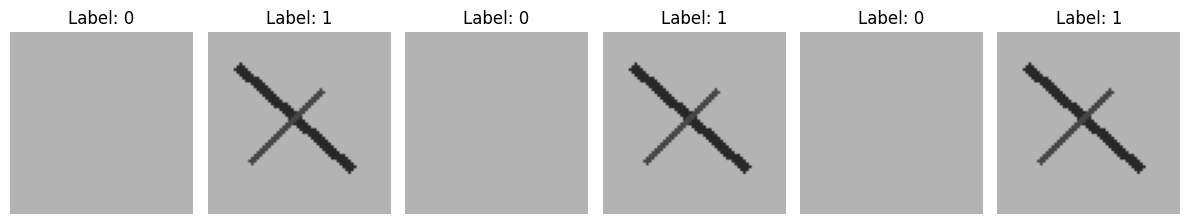

Number of images: 6
Image shape: (64, 64)


In [9]:

from PIL import Image, ImageDraw
import matplotlib.pyplot as plt
import numpy as np

images = []
image_labels = [0, 1, 0, 1, 0, 1]

for label in image_labels:
    img = Image.new("L", (64, 64), color=180)
    draw = ImageDraw.Draw(img)

    if label == 1:
        # Draw artificial defect marks
        draw.line((10, 12, 50, 48), fill=40, width=3)
        draw.line((15, 45, 40, 20), fill=70, width=2)

    images.append(np.array(img))

fig, axes = plt.subplots(1, 6, figsize=(12, 3))

for i, ax in enumerate(axes):
    ax.imshow(images[i], cmap="gray", vmin=0, vmax=255)
    ax.set_title(f"Label: {image_labels[i]}")
    ax.axis("off")

plt.tight_layout()
plt.show()

print("Number of images:", len(images))
print("Image shape:", images[0].shape)


In [10]:

# Convert images into PyTorch tensors

image_tensors = []

for img in images:
    tensor = torch.tensor(img, dtype=torch.float32)

    # Normalize pixel values from 0–255 to 0–1
    tensor = tensor / 255.0

    # Add the channel dimension
    tensor = tensor.unsqueeze(0)

    image_tensors.append(tensor)

# Combine all images into one tensor
image_tensors = torch.stack(image_tensors)

print("Image tensor shape:", image_tensors.shape)
print("Minimum pixel value:", image_tensors.min().item())
print("Maximum pixel value:", image_tensors.max().item())


Image tensor shape: torch.Size([6, 1, 64, 64])
Minimum pixel value: 0.1568627506494522
Maximum pixel value: 0.7058823704719543


In [11]:

# Select the sensor columns
sensor_data = df[
    ["temperature", "vibration", "pressure"]
].values

# Convert to a PyTorch tensor
sensor_tensors = torch.tensor(
    sensor_data,
    dtype=torch.float32
)

# Normalize each feature to the range 0–1
sensor_min = sensor_tensors.min(dim=0).values
sensor_max = sensor_tensors.max(dim=0).values

sensor_tensors = (
    (sensor_tensors - sensor_min)
    / (sensor_max - sensor_min)
)

print("Sensor tensor shape:", sensor_tensors.shape)
print("\nNormalized sensor data:")
print(sensor_tensors)


Sensor tensor shape: torch.Size([5, 3])

Normalized sensor data:
tensor([[0.0077, 0.0182, 0.0435],
        [0.8762, 0.7727, 0.8696],
        [0.0426, 0.0455, 0.0217],
        [1.0000, 1.0000, 1.0000],
        [0.0000, 0.0000, 0.0000]])


In [12]:

# Get inspection notes
texts = df["inspection_note"].tolist()

# Convert text to lowercase and split into words
tokenized_texts = [
    text.lower().split()
    for text in texts
]

# Build a vocabulary
vocab = {"<PAD>": 0, "<UNK>": 1}

for words in tokenized_texts:
    for word in words:
        if word not in vocab:
            vocab[word] = len(vocab)

print("Vocabulary size:", len(vocab))
print("\nVocabulary:")
print(vocab)

# Convert words into integer IDs
encoded_texts = [
    [vocab[word] for word in words]
    for words in tokenized_texts
]

print("\nFirst encoded note:")
print(encoded_texts[0])


Vocabulary size: 18

Vocabulary:
{'<PAD>': 0, '<UNK>': 1, 'surface': 2, 'looks': 3, 'normal': 4, 'crack': 5, 'detected': 6, 'near': 7, 'edge': 8, 'no': 9, 'visible': 10, 'damage': 11, 'severe': 12, 'vibration': 13, 'and': 14, 'product': 15, 'passed': 16, 'inspection': 17}

First encoded note:
[2, 3, 4]


In [13]:

from torch.nn.utils.rnn import pad_sequence

# Convert each encoded note into a tensor
text_tensors = [
    torch.tensor(note, dtype=torch.long)
    for note in encoded_texts
]

# Pad all notes to the length of the longest note
text_tensors = pad_sequence(
    text_tensors,
    batch_first=True,
    padding_value=0
)

print("Text tensor shape:", text_tensors.shape)
print("\nPadded text sequences:")
print(text_tensors)


Text tensor shape: torch.Size([5, 5])

Padded text sequences:
tensor([[ 2,  3,  4,  0,  0],
        [ 5,  6,  7,  8,  0],
        [ 9, 10, 11,  0,  0],
        [12, 13, 14,  2, 11],
        [15, 16, 17,  0,  0]])


In [14]:

# Keep the same number of images as inspection records
image_tensors = image_tensors[:len(df)]

# Prepare the labels
labels = torch.tensor(
    df["label"].values,
    dtype=torch.float32
)

print("Images:", image_tensors.shape)
print("Sensors:", sensor_tensors.shape)
print("Text:", text_tensors.shape)
print("Labels:", labels.shape)

# Verify sample counts
assert len(image_tensors) == len(sensor_tensors)
assert len(sensor_tensors) == len(text_tensors)
assert len(text_tensors) == len(labels)

print("\nAll modalities are aligned!")


Images: torch.Size([5, 1, 64, 64])
Sensors: torch.Size([5, 3])
Text: torch.Size([5, 5])
Labels: torch.Size([5])

All modalities are aligned!


Image shape: torch.Size([5, 1, 64, 64])
Labels: [0.0, 1.0, 0.0, 1.0, 0.0]


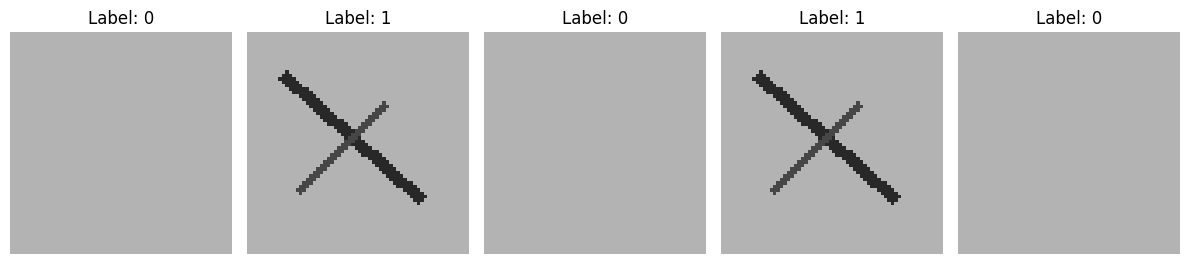

In [15]:

from PIL import Image, ImageDraw
import numpy as np
import torch
import matplotlib.pyplot as plt

# Use the labels from our main dataset
image_labels = df["label"].tolist()

images = []

for label in image_labels:
    img = Image.new("L", (64, 64), color=180)
    draw = ImageDraw.Draw(img)

    if label == 1:
        # Simulate a defective surface
        draw.line((10, 12, 50, 48), fill=40, width=3)
        draw.line((15, 45, 40, 20), fill=70, width=2)

    images.append(np.array(img))

# Convert the corrected images into normalized tensors
image_tensors = torch.tensor(
    np.array(images),
    dtype=torch.float32
).unsqueeze(1) / 255.0

labels = torch.tensor(image_labels, dtype=torch.float32)

print("Image shape:", image_tensors.shape)
print("Labels:", labels.tolist())

# Display images alongside their correct labels
fig, axes = plt.subplots(1, len(images), figsize=(12, 3))

for i, ax in enumerate(axes):
    ax.imshow(images[i], cmap="gray", vmin=0, vmax=255)
    ax.set_title(f"Label: {image_labels[i]}")
    ax.axis("off")

plt.tight_layout()
plt.show()


In [17]:

import torch.nn as nn

class ImageEncoder(nn.Module):
    def __init__(self):
        super().__init__()

        self.network = nn.Sequential(
            nn.Conv2d(1, 16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Flatten(),
            nn.Linear(32 * 16 * 16, 64),
            nn.ReLU()
        )

    def forward(self, x):
        return self.network(x)


image_model = ImageEncoder().to(device)

print(image_model)


image_model.eval()

with torch.no_grad():
    image_features = image_model(image_tensors.to(device))

print("Image input shape:", image_tensors.shape)
print("Image feature shape:", image_features.shape)



ImageEncoder(
  (network): Sequential(
    (0): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Flatten(start_dim=1, end_dim=-1)
    (7): Linear(in_features=8192, out_features=64, bias=True)
    (8): ReLU()
  )
)
Image input shape: torch.Size([5, 1, 64, 64])
Image feature shape: torch.Size([5, 64])


In [19]:

class SensorEncoder(nn.Module):
    def __init__(self):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(3, 16),
            nn.ReLU(),

            nn.Linear(16, 32),
            nn.ReLU(),

            nn.Linear(32, 16),
            nn.ReLU()
        )

    def forward(self, x):
        return self.network(x)


sensor_model = SensorEncoder().to(device)

print(sensor_model)


sensor_model.eval()

with torch.no_grad():
    sensor_features = sensor_model(
        sensor_tensors.to(device)
    )

print("Sensor input shape:", sensor_tensors.shape)
print("Sensor feature shape:", sensor_features.shape)



SensorEncoder(
  (network): Sequential(
    (0): Linear(in_features=3, out_features=16, bias=True)
    (1): ReLU()
    (2): Linear(in_features=16, out_features=32, bias=True)
    (3): ReLU()
    (4): Linear(in_features=32, out_features=16, bias=True)
    (5): ReLU()
  )
)
Sensor input shape: torch.Size([5, 3])
Sensor feature shape: torch.Size([5, 16])


In [20]:
class TextEncoder(nn.Module):
    def __init__(self, vocab_size, embedding_dim=16):
        super().__init__()

        self.embedding = nn.Embedding(
            vocab_size,
            embedding_dim,
            padding_idx=0
        )

        self.network = nn.Sequential(
            nn.Linear(embedding_dim, 32),
            nn.ReLU(),
            nn.Linear(32, 16),
            nn.ReLU()
        )

    def forward(self, x):
        # Convert word IDs into vectors
        embedded = self.embedding(x)

        # Ignore padding tokens
        mask = (x != 0).unsqueeze(-1)

        # Calculate the average word vector
        summed = (embedded * mask).sum(dim=1)
        lengths = mask.sum(dim=1).clamp(min=1)
        averaged = summed / lengths

        # Generate text features
        return self.network(averaged)


text_model = TextEncoder(len(vocab)).to(device)

# Test the encoder
text_model.eval()

with torch.no_grad():
    text_features = text_model(text_tensors.to(device))

print("Vocabulary size:", len(vocab))
print("Text input shape:", text_tensors.shape)
print("Text feature shape:", text_features.shape)

Vocabulary size: 18
Text input shape: torch.Size([5, 5])
Text feature shape: torch.Size([5, 16])


In [21]:
class TriSenseAI(nn.Module):
    def __init__(self, vocab_size):
        super().__init__()

        # Three separate encoders
        self.image_encoder = ImageEncoder()
        self.sensor_encoder = SensorEncoder()
        self.text_encoder = TextEncoder(vocab_size)

        # Combine 64 + 16 + 16 = 96 features
        self.classifier = nn.Sequential(
            nn.Linear(96, 32),
            nn.ReLU(),
            nn.Linear(32, 1)
        )

    def forward(self, images, sensors, texts):
        # Extract features from each data type
        image_features = self.image_encoder(images)
        sensor_features = self.sensor_encoder(sensors)
        text_features = self.text_encoder(texts)

        # Join all features together
        combined = torch.cat(
            [image_features, sensor_features, text_features],
            dim=1
        )

        # Predict a defect score (raw logit)
        return self.classifier(combined)


model = TriSenseAI(len(vocab)).to(device)

print("TriSense AI model created successfully!")
print("Total parameters:", sum(p.numel() for p in model.parameters()))

TriSense AI model created successfully!
Total parameters: 534785


In [22]:
# Set the model to evaluation mode
model.eval()

# Send all three inputs through the model
with torch.no_grad():
    outputs = model(
        image_tensors.to(device),
        sensor_tensors.to(device),
        text_tensors.to(device)
    )

print("Image input shape:", image_tensors.shape)
print("Sensor input shape:", sensor_tensors.shape)
print("Text input shape:", text_tensors.shape)

print("Model output shape:", outputs.shape)
print("\nRaw prediction scores:")
print(outputs)

Image input shape: torch.Size([5, 1, 64, 64])
Sensor input shape: torch.Size([5, 3])
Text input shape: torch.Size([5, 5])
Model output shape: torch.Size([5, 1])

Raw prediction scores:
tensor([[-0.0173],
        [-0.0166],
        [-0.0142],
        [-0.0190],
        [-0.0136]], device='cuda:0')


In [23]:
# Loss function for binary classification
loss_function = nn.BCEWithLogitsLoss()

# Optimizer that updates model weights
optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

# Prepare the correct labels
labels = torch.tensor(
    df["label"].values,
    dtype=torch.float32
).reshape(-1, 1).to(device)

print("Loss function:", loss_function)
print("Optimizer:", optimizer.__class__.__name__)
print("Learning rate:", optimizer.param_groups[0]["lr"])
print("Labels shape:", labels.shape)
print("Labels:", labels.squeeze().tolist())

Loss function: BCEWithLogitsLoss()
Optimizer: Adam
Learning rate: 0.001
Labels shape: torch.Size([5, 1])
Labels: [0.0, 1.0, 0.0, 1.0, 0.0]


In [25]:
# Training settings
epochs = 200

# Prepare training inputs
images = image_tensors.to(device)
sensors = sensor_tensors.to(device)
texts = text_tensors.to(device)

# Start training
model.train()

for epoch in range(epochs):

    # Forward pass: predict defect scores
    outputs = model(images, sensors, texts)

    # Measure prediction error
    loss = loss_function(outputs, labels)

    # Clear previous gradients
    optimizer.zero_grad()

    # Calculate gradients
    loss.backward()

    # Update model weights
    optimizer.step()

    # Display progress
    if (epoch + 1) % 20 == 0:
        print(
            f"Epoch [{epoch + 1}/{epochs}], "
            f"Loss: {loss.item():.4f}"
        )

print("\nTraining completed!")

Epoch [20/200], Loss: 0.4820
Epoch [40/200], Loss: 0.0200
Epoch [60/200], Loss: 0.0005
Epoch [80/200], Loss: 0.0002
Epoch [100/200], Loss: 0.0001
Epoch [120/200], Loss: 0.0001
Epoch [140/200], Loss: 0.0001
Epoch [160/200], Loss: 0.0001
Epoch [180/200], Loss: 0.0001
Epoch [200/200], Loss: 0.0001

Training completed!


In [26]:
# Switch to evaluation mode
model.eval()

# Generate predictions
with torch.no_grad():
    logits = model(images, sensors, texts)

    # Convert raw scores into probabilities
    probabilities = torch.sigmoid(logits)

    # Convert probabilities into class predictions
    predictions = (probabilities >= 0.5).float()

# Calculate accuracy on the training examples
correct = (predictions == labels).sum().item()
total = labels.size(0)
accuracy = (correct / total) * 100

print("TRISENSE AI EVALUATION")
print("-" * 35)

for i in range(total):
    actual = int(labels[i].item())
    predicted = int(predictions[i].item())
    probability = probabilities[i].item()

    print(
        f"Product {i + 1}: "
        f"Actual={actual}, "
        f"Predicted={predicted}, "
        f"Defect probability={probability:.2%}"
    )

print("-" * 35)
print(f"Training accuracy: {accuracy:.2f}%")

TRISENSE AI EVALUATION
-----------------------------------
Product 1: Actual=0, Predicted=0, Defect probability=0.00%
Product 2: Actual=1, Predicted=1, Defect probability=99.99%
Product 3: Actual=0, Predicted=0, Defect probability=0.00%
Product 4: Actual=1, Predicted=1, Defect probability=99.99%
Product 5: Actual=0, Predicted=0, Defect probability=0.01%
-----------------------------------
Training accuracy: 100.00%


In [27]:
# Save the trained model weights
model_path = "/content/trisense_ai.pth"

torch.save(model.state_dict(), model_path)

print("TriSense AI model saved successfully!")
print("Saved location:", model_path)

# Check the saved file size
import os

file_size = os.path.getsize(model_path) / 1024

print(f"File size: {file_size:.2f} KB")

TriSense AI model saved successfully!
Saved location: /content/trisense_ai.pth
File size: 2097.39 KB


In [28]:
# Create a fresh model with the same architecture
loaded_model = TriSenseAI(len(vocab)).to(device)

# Load the saved weights
loaded_model.load_state_dict(
    torch.load(model_path, map_location=device, weights_only=True)
)

# Switch to evaluation mode
loaded_model.eval()

# Test the restored model
with torch.no_grad():
    loaded_logits = loaded_model(images, sensors, texts)
    loaded_probabilities = torch.sigmoid(loaded_logits)

print("Model reloaded successfully!")
print("Restored output shape:", loaded_logits.shape)
print("\nRestored defect probabilities:")

for i, probability in enumerate(loaded_probabilities):
    print(f"Product {i + 1}: {probability.item():.2%}")

Model reloaded successfully!
Restored output shape: torch.Size([5, 1])

Restored defect probabilities:
Product 1: 0.00%
Product 2: 99.99%
Product 3: 0.00%
Product 4: 99.99%
Product 5: 0.01%


In [29]:
def predict_defect(image, sensor_values, inspection_note):
    loaded_model.eval()

    # Prepare the image
    image_input = torch.tensor(
        image, dtype=torch.float32
    ).unsqueeze(0).unsqueeze(0).to(device)

    # Normalize sensor values using Cell 6's scaling
    sensor_values = torch.tensor(
        sensor_values, dtype=torch.float32
    )

    sensor_input = (
        (sensor_values - sensor_min.cpu()) /
        (sensor_max.cpu() - sensor_min.cpu())
    ).unsqueeze(0).to(device)

    # Convert inspection note into word IDs
    words = inspection_note.lower().split()
    encoded = [vocab.get(word, vocab["<UNK>"]) for word in words]

    if not encoded:
        encoded = [vocab["<UNK>"]]

    text_input = torch.tensor(
        encoded, dtype=torch.long
    ).unsqueeze(0).to(device)

    # Generate prediction
    with torch.no_grad():
        logit = loaded_model(
            image_input,
            sensor_input,
            text_input
        )
        probability = torch.sigmoid(logit).item()

    prediction = "DEFECTIVE" if probability >= 0.5 else "NORMAL"

    return {
        "prediction": prediction,
        "defect_probability": round(probability * 100, 2)
    }


# Test using the first synthetic product
result = predict_defect(
    images[0, 0].cpu().numpy(),
    df.loc[0, ["temperature", "vibration", "pressure"]].values.astype(float),
    df.loc[0, "inspection_note"]
)

print("TRISENSE AI ASSESSMENT")
print("-" * 30)
print("Prediction:", result["prediction"])
print("Defect probability:", str(result["defect_probability"]) + "%")

TRISENSE AI ASSESSMENT
------------------------------
Prediction: NORMAL
Defect probability: 0.0%


In [30]:
def inspection_decision(result):
    probability = result["defect_probability"]

    if probability >= 70:
        decision = "REJECT / INSPECT"
        reason = "High predicted defect probability"

    elif probability >= 40:
        decision = "MANUAL REVIEW"
        reason = "Uncertain result; additional inspection recommended"

    else:
        decision = "PASS CANDIDATE"
        reason = "Low predicted defect probability"

    return {
        "prediction": result["prediction"],
        "defect_probability": probability,
        "inspection_decision": decision,
        "reason": reason
    }


# Apply the decision layer
assessment = inspection_decision(result)

print("TRISENSE AI — INSPECTION REPORT")
print("=" * 40)

for key, value in assessment.items():
    print(f"{key.replace('_', ' ').title()}: {value}")

TRISENSE AI — INSPECTION REPORT
Prediction: NORMAL
Defect Probability: 0.0
Inspection Decision: PASS CANDIDATE
Reason: Low predicted defect probability


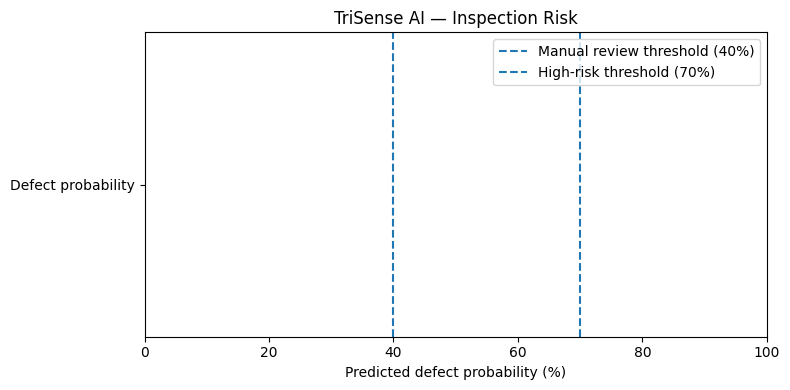

Final recommendation: PASS CANDIDATE


In [31]:
# Get the prediction probability
probability = assessment["defect_probability"]

# Plot the result
plt.figure(figsize=(8, 4))

plt.barh(
    ["Defect probability"],
    [probability]
)

plt.axvline(
    40,
    linestyle="--",
    label="Manual review threshold (40%)"
)

plt.axvline(
    70,
    linestyle="--",
    label="High-risk threshold (70%)"
)

plt.xlim(0, 100)
plt.xlabel("Predicted defect probability (%)")
plt.title("TriSense AI — Inspection Risk")
plt.legend()
plt.tight_layout()
plt.show()

print("Final recommendation:", assessment["inspection_decision"])

In [32]:
import json

# Save the text vocabulary
vocab_path = "/content/trisense_vocab.json"

with open(vocab_path, "w") as file:
    json.dump(vocab, file, indent=4)

# Save sensor normalization values
preprocessing = {
    "sensor_columns": [
        "temperature",
        "vibration",
        "pressure"
    ],
    "sensor_min": sensor_min.tolist(),
    "sensor_max": sensor_max.tolist(),
    "image_size": [64, 64],
    "image_channels": 1,
    "classification_labels": {
        "0": "NORMAL",
        "1": "DEFECTIVE"
    }
}

preprocessing_path = "/content/trisense_preprocessing.json"

with open(preprocessing_path, "w") as file:
    json.dump(preprocessing, file, indent=4)

print("Supporting files saved successfully!")
print("\nFiles:")
print(model_path)
print(vocab_path)
print(preprocessing_path)

Supporting files saved successfully!

Files:
/content/trisense_ai.pth
/content/trisense_vocab.json
/content/trisense_preprocessing.json


In [33]:
import os
import json

# Check that all three files exist
required_files = [
    model_path,
    vocab_path,
    preprocessing_path
]

print("TRISENSE AI — FILE VERIFICATION")
print("-" * 40)

for path in required_files:
    if os.path.exists(path):
        print(f"FOUND: {os.path.basename(path)}")
    else:
        print(f"MISSING: {os.path.basename(path)}")

# Reload the vocabulary
with open(vocab_path, "r") as file:
    loaded_vocab = json.load(file)

# Reload preprocessing settings
with open(preprocessing_path, "r") as file:
    loaded_preprocessing = json.load(file)

print("\nVocabulary entries:", len(loaded_vocab))
print("Sensor columns:", loaded_preprocessing["sensor_columns"])
print("Image size:", loaded_preprocessing["image_size"])
print("Labels:", loaded_preprocessing["classification_labels"])

TRISENSE AI — FILE VERIFICATION
----------------------------------------
FOUND: trisense_ai.pth
FOUND: trisense_vocab.json
FOUND: trisense_preprocessing.json

Vocabulary entries: 18
Sensor columns: ['temperature', 'vibration', 'pressure']
Image size: [64, 64]
Labels: {'0': 'NORMAL', '1': 'DEFECTIVE'}


In [34]:
import zipfile
import os

zip_path = "/content/trisense_ai_package.zip"

files_to_package = [
    model_path,
    vocab_path,
    preprocessing_path
]

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as zip_file:
    for path in files_to_package:
        zip_file.write(path, arcname=os.path.basename(path))

print("TriSense AI package created!")
print("Package:", zip_path)
print(
    "Package size:",
    round(os.path.getsize(zip_path) / 1024, 2),
    "KB"
)

# Download the package from Google Colab
from google.colab import files
files.download(zip_path)

TriSense AI package created!
Package: /content/trisense_ai_package.zip
Package size: 1937.34 KB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [35]:
import os
import torch

print("=" * 45)
print("       TRISENSE AI — FINAL AUDIT")
print("=" * 45)

# 1. Check all three encoders
print("\n1. MULTIMODAL ARCHITECTURE")
print("Image encoder:", type(model.image_encoder).__name__)
print("Sensor encoder:", type(model.sensor_encoder).__name__)
print("Text encoder:", type(model.text_encoder).__name__)

# 2. Count model parameters
parameters = sum(
    p.numel() for p in model.parameters()
)

print("\n2. MODEL SIZE")
print("Trainable parameters:", parameters)

# 3. Check saved artifacts
print("\n3. SAVED ARTIFACTS")

for path in [
    model_path,
    vocab_path,
    preprocessing_path,
    "/content/trisense_ai_package.zip"
]:
    status = "FOUND" if os.path.exists(path) else "MISSING"
    print(f"{os.path.basename(path)}: {status}")

# 4. Check prediction pipeline
print("\n4. PREDICTION PIPELINE")

if "assessment" in globals():
    print("Prediction:", assessment["prediction"])
    print("Decision:", assessment["inspection_decision"])
    print("Defect probability:", assessment["defect_probability"], "%")
else:
    print("Assessment not available. Run the prediction cells first.")

print("\n5. DATASET LIMITATION")
print("Synthetic samples:", len(df))
print("Real-world validation: NOT PERFORMED")

print("\nFinal audit complete.")

       TRISENSE AI — FINAL AUDIT

1. MULTIMODAL ARCHITECTURE
Image encoder: ImageEncoder
Sensor encoder: SensorEncoder
Text encoder: TextEncoder

2. MODEL SIZE
Trainable parameters: 534785

3. SAVED ARTIFACTS
trisense_ai.pth: FOUND
trisense_vocab.json: FOUND
trisense_preprocessing.json: FOUND
trisense_ai_package.zip: FOUND

4. PREDICTION PIPELINE
Prediction: NORMAL
Decision: PASS CANDIDATE
Defect probability: 0.0 %

5. DATASET LIMITATION
Synthetic samples: 5
Real-world validation: NOT PERFORMED

Final audit complete.
